# Experiment 029: MC-SFT to GRPO at 1.5B and 3B

What happened when GRPO is added after MC-SFT at 1.5B and 3B. It compares the six run outcomes and the reward variation available before training. Only the completed 1.5B seed 1 arm has an endpoint, so its comparison is descriptive rather than a three-seed result.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / 'config.py').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

RES = ROOT / 'results'
FIG = ROOT / 'analysis' / 'figures' / '029_1'
FIG.mkdir(parents=True, exist_ok=True)
GROUPS = ('overall', 'easy', 'medium', 'hard')

def jload(path):
    with open(path) as handle:
        return json.load(handle)

def jsonl(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]

def accuracy(rows):
    return float(np.mean([bool(row['correct']) for row in rows]))

def save(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=300, bbox_inches='tight')

ARMS = [(scale, seed) for scale in ('B15', 'B3') for seed in (0, 1, 2)]
LABELS = [f"{'1.5B' if scale == 'B15' else '3B'} s{seed}" for scale, seed in ARMS]
plt.style.use('seaborn-v0_8-whitegrid')
print('figures ->', FIG.relative_to(ROOT))

figures -> analysis/figures/029_1


## Outcomes and pool diagnostics

,scale,seed,outcome,decision step,last checkpoint,minutes,peak VRAM GiB
0,1.5B,0,A2 sentinel,150,100,6.323,9.69
1,1.5B,1,completed,500,500,18.288,9.96
2,1.5B,2,A2 sentinel,150,100,6.313,9.96
3,3B,0,A2 sentinel,150,100,7.825,16.56
4,3B,1,A2 sentinel,150,100,8.100,16.56
5,3B,2,A2 sentinel,150,100,7.757,16.92


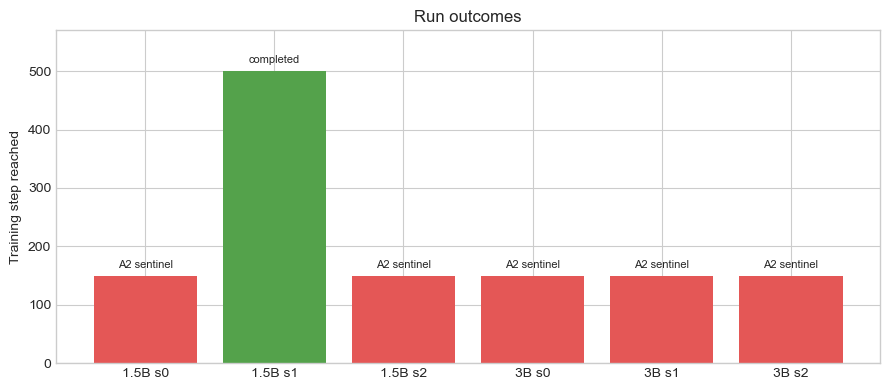

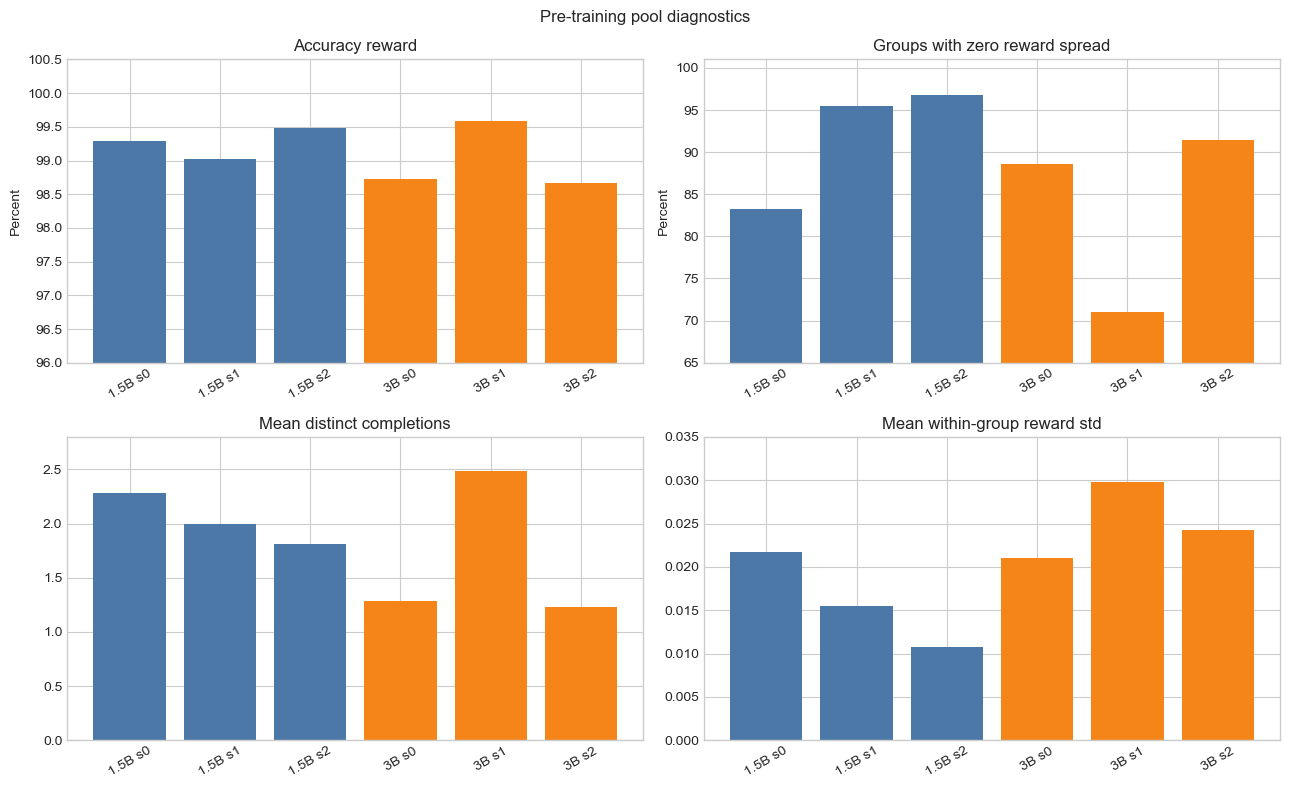

In [2]:
status_rows = []
pool_rows = []
for scale, seed in ARMS:
    tag = f'029_COLAB_FULL_{scale}_mcsft_grpo_seed{seed}'
    path = RES / tag
    attempt = jload(path / 'arm_manifest.json')['attempts'][-1]
    stopped = (path / 'concluded_a2.json').exists()
    status_rows.append({
        'scale': '1.5B' if scale == 'B15' else '3B',
        'seed': seed,
        'outcome': 'A2 sentinel' if stopped else 'completed',
        'decision step': 150 if stopped else attempt['end_step'],
        'last checkpoint': attempt['end_step'],
        'minutes': attempt['elapsed_sec'] / 60,
        'peak VRAM GiB': attempt['peak_vram_gib'],
    })
    pool = jload(path / 'pool_variability.json')
    pool_rows.append({
        'scale': '1.5B' if scale == 'B15' else '3B',
        'seed': seed,
        'pool accuracy': pool['mean_accuracy_reward'],
        'zero reward spread': pool['share_zero_reward_spread'],
        'distinct completions': pool['mean_distinct_completions'],
        'single answer': pool['share_single_answer'],
        'reward std': pool['mean_reward_std'],
        'format rate': pool['format_rate'],
    })

status_tbl = pd.DataFrame(status_rows)
pool_tbl = pd.DataFrame(pool_rows)
display(status_tbl.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
colors = ['#E45756' if value == 'A2 sentinel' else '#54A24B' for value in status_tbl['outcome']]
bars = ax.bar(LABELS, status_tbl['decision step'], color=colors)
for bar, outcome in zip(bars, status_tbl['outcome']):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 10, outcome,
            ha='center', va='bottom', fontsize=8)
ax.set_ylim(0, 570)
ax.set_ylabel('Training step reached')
ax.set_title('Run outcomes')
fig.tight_layout()
save(fig, 'fig01_run_outcomes')
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
metrics = [
    ('pool accuracy', 'Accuracy reward', (0.96, 1.005), 100),
    ('zero reward spread', 'Groups with zero reward spread', (0.65, 1.01), 100),
    ('distinct completions', 'Mean distinct completions', (0, 2.8), 1),
    ('reward std', 'Mean within-group reward std', (0, 0.035), 1),
]
scale_colors = ['#4C78A8'] * 3 + ['#F58518'] * 3
for ax, (metric, title, ylim, factor) in zip(axes.flat, metrics):
    ax.bar(LABELS, pool_tbl[metric] * factor, color=scale_colors)
    ax.set_title(title)
    ax.set_ylim(ylim[0] * factor, ylim[1] * factor)
    ax.tick_params(axis='x', rotation=30)
    if factor == 100:
        ax.set_ylabel('Percent')
fig.suptitle('Pre-training pool diagnostics')
fig.tight_layout()
save(fig, 'fig02_pool_diagnostics')
plt.show()

## Completed 1.5B seed 1 endpoint

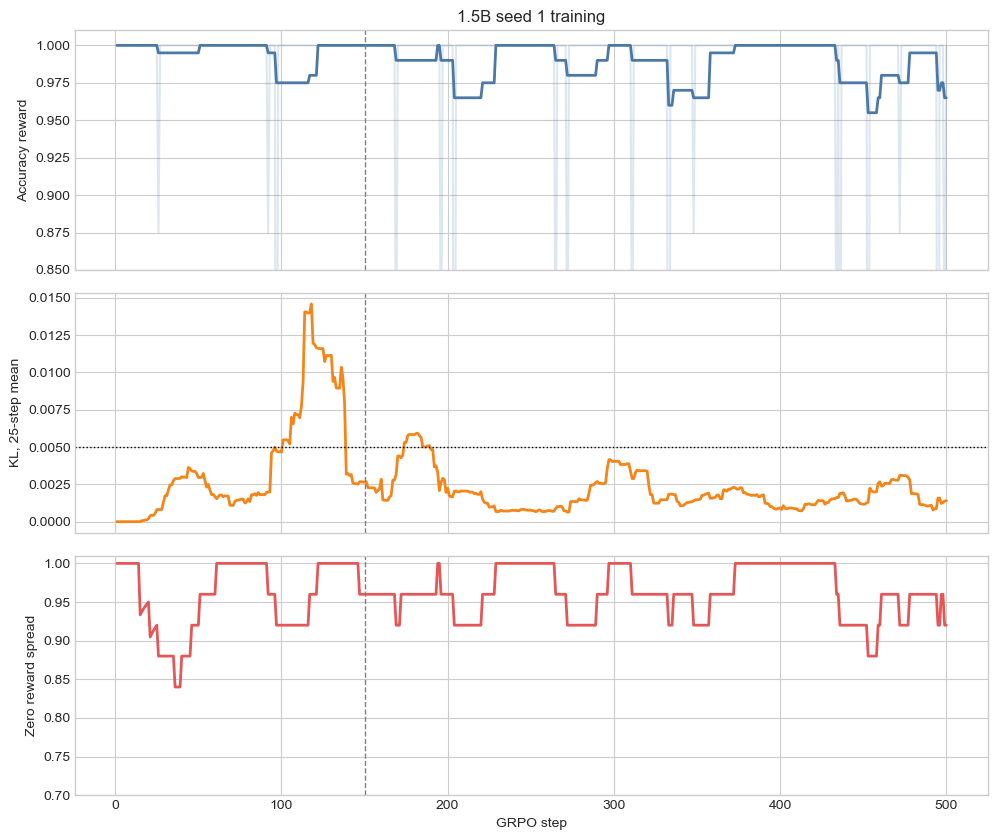

In [3]:
trainlog = jload(RES / '029_COLAB_FULL_B15_mcsft_grpo_seed1' / 'grpo_trainlog.json')
train = pd.DataFrame([row for row in trainlog if 'rewards/accuracy_reward/mean' in row])
smooth = train.set_index('step')[[
    'rewards/accuracy_reward/mean', 'kl', 'frac_reward_zero_std'
]].rolling(25, min_periods=1).mean()

fig, axes = plt.subplots(3, 1, figsize=(10, 8.5), sharex=True)
axes[0].plot(train['step'], train['rewards/accuracy_reward/mean'], color='#4C78A8', alpha=0.18)
axes[0].plot(smooth.index, smooth['rewards/accuracy_reward/mean'], color='#4C78A8', lw=2)
axes[0].set_ylabel('Accuracy reward')
axes[0].set_ylim(0.85, 1.01)
axes[1].plot(smooth.index, smooth['kl'], color='#F58518', lw=2)
axes[1].axhline(0.005, color='black', ls=':', lw=1)
axes[1].set_ylabel('KL, 25-step mean')
axes[2].plot(smooth.index, smooth['frac_reward_zero_std'], color='#E45756', lw=2)
axes[2].set_ylabel('Zero reward spread')
axes[2].set_xlabel('GRPO step')
axes[2].set_ylim(0.7, 1.01)
for ax in axes:
    ax.axvline(150, color='grey', ls='--', lw=1)
axes[0].set_title('1.5B seed 1 training')
fig.tight_layout()
save(fig, 'fig03_seed1_training')
plt.show()

group                         overall    easy  medium    hard
recipe            metric                                     
GSM8K-SFT -> GRPO generative   0.6348  0.7679  0.5977  0.3965
                  probe        0.6980  0.8134  0.6995  0.4394
MC-SFT -> GRPO    generative   0.6911  0.8032  0.6880  0.4470
                  probe        0.6959  0.8203  0.6929  0.4242
MC-SFT parent     generative   0.6906  0.7998  0.6880  0.4520
                  probe        0.6980  0.8214  0.6946  0.4293

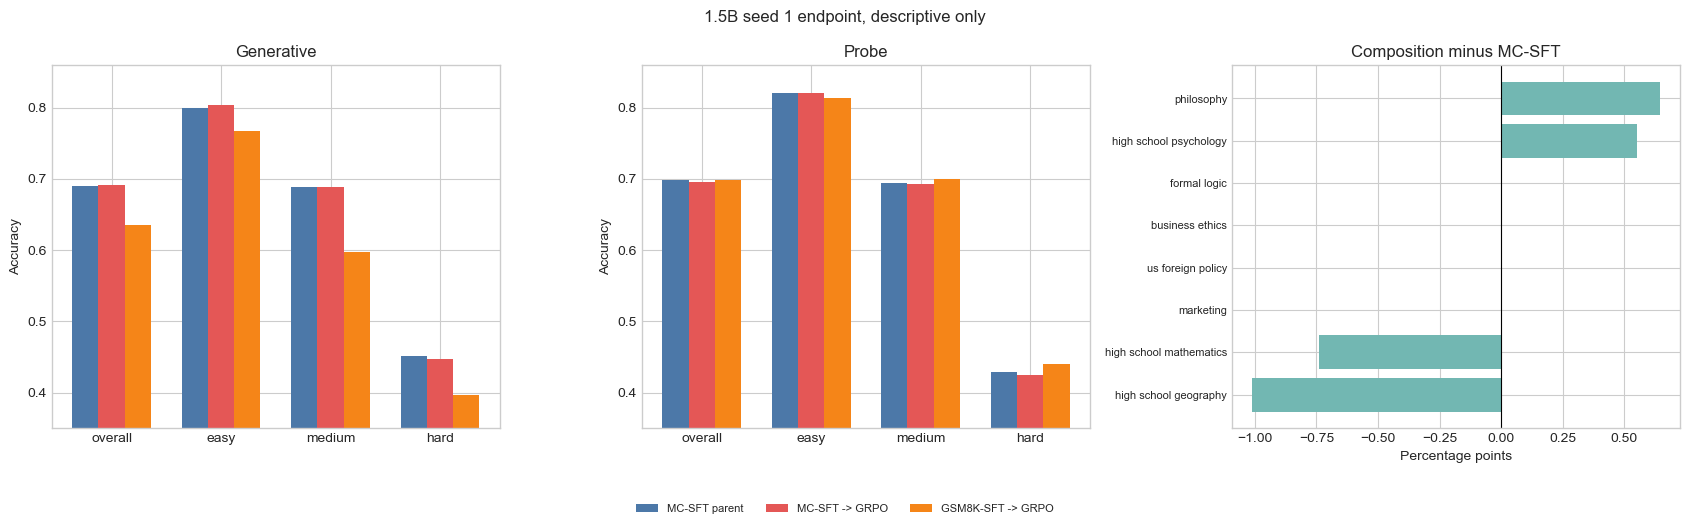

Five sentinel stops leave one endpoint, so no formal family-level comparison is reported.


In [4]:
run_specs = {
    'MC-SFT parent': ('010_p8_COLAB_FULL_B15_sft_only_seed1', 'sft'),
    'MC-SFT -> GRPO': ('029_COLAB_FULL_B15_mcsft_grpo_seed1', 'grpo'),
    'GSM8K-SFT -> GRPO': ('009_COLAB_FULL_B15_sft_grpo_seed1', 'grpo'),
}
endpoint_rows = []
subject_rows = []
loaded = {}
for recipe, (tag, prefix) in run_specs.items():
    path = RES / tag
    gen = jload(path / f'{prefix}_eval.json')
    probe = jload(path / f'{prefix}_logprob.json')
    gen_rows = jsonl(path / f'{prefix}_preds.jsonl')
    probe_rows = jsonl(path / f'{prefix}_logprob_preds.jsonl')
    loaded[recipe] = {'gen': gen, 'probe': probe}
    for metric, values, rows in (
        ('generative', gen['per_tier_acc'], gen_rows),
        ('probe', probe['per_tier_acc'], probe_rows),
    ):
        scores = {'overall': accuracy(rows), **values}
        for group in GROUPS:
            endpoint_rows.append({
                'recipe': recipe, 'metric': metric,
                'group': group, 'accuracy': scores[group],
            })

parent_subjects = loaded['MC-SFT parent']['gen']['per_subject_acc']
composition_subjects = loaded['MC-SFT -> GRPO']['gen']['per_subject_acc']
for subject in parent_subjects:
    subject_rows.append({
        'subject': subject,
        'change': composition_subjects[subject] - parent_subjects[subject],
    })
endpoint_tbl = pd.DataFrame(endpoint_rows)
subject_tbl = pd.DataFrame(subject_rows).sort_values('change')
display(endpoint_tbl.pivot_table(
    index=['recipe', 'metric'], columns='group', values='accuracy'
)[list(GROUPS)].round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
x = np.arange(len(GROUPS))
width = 0.24
palette = ['#4C78A8', '#E45756', '#F58518']
for ax, metric in zip(axes[:2], ('generative', 'probe')):
    for index, (recipe, color) in enumerate(zip(run_specs, palette)):
        values = (endpoint_tbl.query('metric == @metric and recipe == @recipe')
                  .set_index('group').loc[list(GROUPS), 'accuracy'])
        ax.bar(x + (index - 1) * width, values, width, label=recipe, color=color)
    ax.set_xticks(x)
    ax.set_xticklabels(GROUPS)
    ax.set_ylim(0.35, 0.86)
    ax.set_title(metric.capitalize())
    ax.set_ylabel('Accuracy')
y = np.arange(len(subject_tbl))
axes[2].barh(y, subject_tbl['change'] * 100, color='#72B7B2')
axes[2].axvline(0, color='black', lw=0.8)
axes[2].set_yticks(y)
axes[2].set_yticklabels(subject_tbl['subject'].str.replace('_', ' '), fontsize=8)
axes[2].set_xlabel('Percentage points')
axes[2].set_title('Composition minus MC-SFT')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, fontsize=8)
fig.suptitle('1.5B seed 1 endpoint, descriptive only')
fig.tight_layout(rect=[0, 0.08, 1, 1])
save(fig, 'fig04_seed1_endpoint')
plt.show()
print('Five sentinel stops leave one endpoint, so no formal family-level comparison is reported.')

## Exact values

In [5]:
status_tbl.to_csv(FIG / 'run_outcomes.csv', index=False)
pool_tbl.to_csv(FIG / 'pool_diagnostics.csv', index=False)
endpoint_tbl.to_csv(FIG / 'seed1_endpoints.csv', index=False)
subject_tbl.to_csv(FIG / 'seed1_subject_changes.csv', index=False)
display(pool_tbl.set_index(['scale', 'seed']).round(4))
display(subject_tbl.set_index('subject').round(4))

pool accuracy  zero reward spread  distinct completions  \
scale seed                                                            
1.5B  0            0.9929              0.8327                2.2816   
      1            0.9903              0.9551                2.0000   
      2            0.9949              0.9673                1.8082   
3B    0            0.9872              0.8857                1.2898   
      1            0.9959              0.7102                2.4816   
      2            0.9867              0.9143                1.2327   

            single answer  reward std  format rate  
scale seed                                          
1.5B  0            0.9714      0.0217       0.9714  
      1            0.9633      0.0155       0.9969  
      2            0.9714      0.0108       0.9995  
3B    0            0.9551      0.0210       0.9908  
      1            0.9673      0.0299       0.9541  
      2            0.9347      0.0243       0.9959

,change
subject,
high_school_geography,-0.0101
high_school_mathematics,-0.0074
marketing,0.0000
us_foreign_policy,0.0000
business_ethics,0.0000
formal_logic,0.0000
high_school_psychology,0.0055
philosophy,0.0064


## Cross-referenced conclusion

Five of the six arms have reached the registered A2 stop, including all three 3B seeds. The pool diagnostic explains this: MC-SFT already answered 98.7-99.6% of the sampled training completions correctly, and 71.0 - 96.7% of groups had no reward spread. The only completed arm, 1.5B seed 1, changed overall generative accuracy by +0.05 percentage points and hard accuracy by -0.51 points compared with its MC-SFT parent, so GRPO did not give a useful improvement there. This agrees with experiment 028 at 7B: after MC-SFT, the small training pool leaves very little group-relative signal. Because only one endpoint completed, it's a mechanism result rather than a formal three-seed endpoint comparison.